Dataset Shape: (442, 11)

First Five Records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Ensemble Model Performance Comparison:


,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.453,53.853,42.794
1,Bagging,0.439,54.506,44.441
2,Boosting,0.482,52.373,42.546
3,Stacking,0.461,53.431,42.804


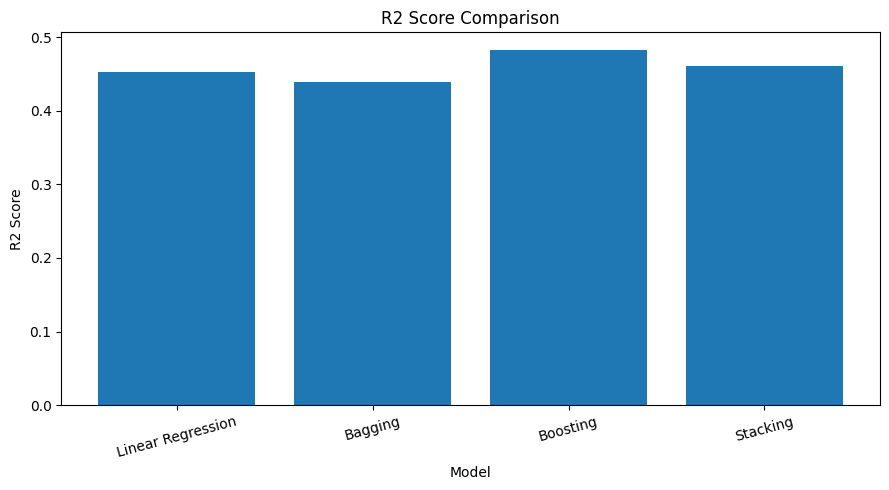

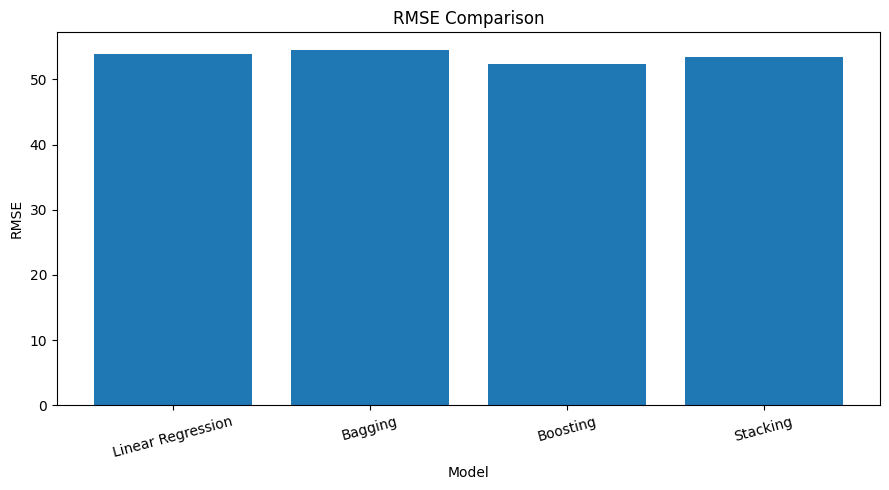

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    GradientBoostingRegressor,
    StackingRegressor)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load Dataset
data = load_diabetes(as_frame=True)
df = data.frame

X = df.drop(columns="target")
y = df["target"]

print("Dataset Shape:", df.shape)
print("\nFirst Five Records:")
display(df.head())

# 2. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

# 3. Define Models
models = {"Linear Regression": LinearRegression(),

    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        random_state=42),

    "Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42),

    "Stacking": StackingRegressor(
        estimators=[
            ("linear", LinearRegression()),
            ("tree", DecisionTreeRegressor(max_depth=4)),
            ("bagging", BaggingRegressor(
                estimator=DecisionTreeRegressor(),
                n_estimators=50,
                random_state=42))],final_estimator=LinearRegression())}

# 4. Train and Evaluate Models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions)})

# 5. Display Results
results_df = pd.DataFrame(results)
print("\nEnsemble Model Performance Comparison:")
display(results_df.round(3))

# 6. Plot R2 Score Comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R2 Score Comparison")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 7. Plot RMSE Comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()